In [39]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


En esta actividad usarás el archivo de datos `bigMartSales.csv`.

* `Item_Identifier`: ID de producto único
* `Item_Weight`: Peso del producto
* `Item_Fat_Content`: si el producto es bajo en grasa o no
* `Item_Visibility`: el porcentaje del área de exhibición total de todos los productos en una tienda asignado al producto en particular.
* `Item_Type`: La categoría a la que pertenece el producto.
* `Item_MRP`: Precio de venta máximo (precio de lista) del producto
* `Outlet_Identifier`: ID de tienda única
* `Outlet_Establishment_Year`: El año en que se estableció la tienda.
* `Outlet_Size`: El tamaño de la tienda en términos de superficie cubierta.
* `Outlet_Location_Type`: El tipo de ciudad en la que se encuentra la tienda.
* `Outlet_Type`: si el outlet es solo una tienda de comestibles o algún tipo de supermercado.

* **`Item_Outlet_Sales`**: Ventas del producto en la tienda concreta. Ésta es la variable de resultado que se va a predecir.

In [40]:
# Librerías para manipulación de datos
import numpy as np
import pandas as pd

# Librerías para visualización
import seaborn as sns
import matplotlib.pyplot as plt

# Librerías para preprocesamiento e ing de características
from sklearn.impute import SimpleImputer #rellena datos faltantes (imputar) con mean, median, most_frequent, constant
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
    #MinMaxScaler, normaliza los datos numericos dentro de un rango [0,1]
    #OneHotEncoder, convierte variables categoricas en columnas binarias (0 y 1)

# Librerías para la canalización (pipeline)
from sklearn.compose import ColumnTransformer, make_column_selector
    #ColumnTransformer, aplica diferentes transformaciones a diferentes columnas
    #make_column_selector, selecciona automaticamente columnas segun su tipo de dato
from sklearn.pipeline import make_pipeline
    #encadena los pasos de transformacion y modelado en una sola estructura

# Librerías para la regresión
from sklearn.linear_model import LinearRegression
    #modelo de Regresion Lineal clasico de Scikit-learn
from sklearn.metrics import mean_squared_error, r2_score
    #mean_squared_error (MSE) -> se le saca raiz cuadrada para obtener el RMSE
    #r2_score, proporcion de la varianza de la variable objetivo explicada por el modelo


Descarga el archivo: `bigMartSales.csv` y guarda, en un dataframe (`sales_df`), todos sus registros.

In [41]:
sales_df = pd.read_csv('/content/drive/MyDrive/IA/bigMartSales.csv')
sales_df

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.300,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.920,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.500,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.200,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.930,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052
...,...,...,...,...,...,...,...,...,...,...,...,...
8518,FDF22,6.865,Low Fat,0.056783,Snack Foods,214.5218,OUT013,1987,High,Tier 3,Supermarket Type1,2778.3834
8519,FDS36,8.380,Regular,0.046982,Baking Goods,108.1570,OUT045,2002,NaN,Tier 2,Supermarket Type1,549.2850
8520,NCJ29,10.600,Low Fat,0.035186,Health and Hygiene,85.1224,OUT035,2004,Small,Tier 2,Supermarket Type1,1193.1136
8521,FDN46,7.210,Regular,0.145221,Snack Foods,103.1332,OUT018,2009,Medium,Tier 3,Supermarket Type2,1845.5976


ANALISIS DE DATOS

In [42]:
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [43]:
# Determinando la cantidad de valores únicos por columna
sales_df.nunique()

,0
Item_Identifier,1559
Item_Weight,415
Item_Fat_Content,5
Item_Visibility,7880
Item_Type,16
Item_MRP,5938
Outlet_Identifier,10
Outlet_Establishment_Year,9
Outlet_Size,3
Outlet_Location_Type,3


Como la variable `Item_Identifier` es solo un ID, no se usa directamente como predictor. Antes de eliminarla se guarda en `item_ids` (sirve para rellenar valores faltantes de productos y para crear la categoría general del producto: `FD` = comida, `DR` = bebidas, `NC` = no consumibles).

`Outlet_Identifier` **sí se conserva**: cada tienda tiene un comportamiento de ventas propio (sin importar su tipo o tamaño), y eso mejora mucho el modelo.

In [44]:
# Se guarda el ID del producto y se crea una categoría general con sus 2 primeras letras (FD, DR, NC)
item_ids = sales_df['Item_Identifier'].copy()
sales_df['Item_Category'] = sales_df['Item_Identifier'].str[:2]
sales_df.drop('Item_Identifier', axis=1, inplace=True)

In [45]:
# Estadísticas descriptivas de las variables numéricas
sales_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Item_Weight,7060.0,12.857645,4.643456,4.555,8.773750,12.600000,16.850000,21.350000
Item_Visibility,8523.0,0.066132,0.051598,0.000,0.026989,0.053931,0.094585,0.328391
Item_MRP,8523.0,140.992782,62.275067,31.290,93.826500,143.012800,185.643700,266.888400
Outlet_Establishment_Year,8523.0,1997.831867,8.371760,1985.000,1987.000000,1999.000000,2004.000000,2009.000000
Item_Outlet_Sales,8523.0,2181.288914,1706.499616,33.290,834.247400,1794.331000,3101.296400,13086.964800


In [46]:
# Estadísticas descriptivas de las variables de texto
sales_df.describe(exclude=np.number).T

,count,unique,top,freq
Item_Fat_Content,8523,5,Low Fat,5089
Item_Type,8523,16,Fruits and Vegetables,1232
Outlet_Identifier,8523,10,OUT027,935
Outlet_Size,6113,3,Medium,2793
Outlet_Location_Type,8523,3,Tier 3,3350
Outlet_Type,8523,4,Supermarket Type1,5577
Item_Category,8523,3,FD,6125


In [47]:
# Se hace una lista de variables numéricas y otra de categóricas.
num_cols = sales_df.select_dtypes(include=np.number).columns.tolist()
cat_cols = sales_df.select_dtypes(exclude=np.number).columns.tolist()

In [48]:
# Recuento de cada categoría única en las variables categóricas
for column in cat_cols:
    print(column)
    print(sales_df[column].value_counts())
    print('-' * 50)

Item_Fat_Content
Item_Fat_Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64
--------------------------------------------------
Item_Type
Item_Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks               214
Others                    169
Starchy Foods             148
Breakfast                 110
Seafood                    64
Name: count, dtype: int64
--------------------------------------------------
Outlet_Identifier
Outlet_Identifier
OUT027    935
OUT013    932
OUT035    930
OUT049    930
OUT046    930
OUT045    929
OUT018    928
OUT017    926
OUT010    555
OUT019    528
Name: count, dtype: int64
------------------------------

In [49]:
# Se determinan porcentaje de nulos por columna
sales_df.isnull().mean() * 100

,0
Item_Weight,17.165317
Item_Fat_Content,0.000000
Item_Visibility,0.000000
Item_Type,0.000000
Item_MRP,0.000000
Outlet_Identifier,0.000000
Outlet_Establishment_Year,0.000000
Outlet_Size,28.276428
Outlet_Location_Type,0.000000
Outlet_Type,0.000000


**Limpieza de valores faltantes y valores inválidos**

* `Item_Weight`: un mismo producto siempre pesa lo mismo, así que se rellena con el peso de ese producto en otras tiendas (y con la mediana si el producto aparece una sola vez).
* `Item_Visibility`: hay valores en 0, que no tienen sentido (todo producto ocupa algo de exhibición). Se tratan como faltantes y se rellenan con el promedio de ese producto en otras tiendas.
* `Outlet_Size`: hay tiendas sin tamaño registrado. Se rellena con la moda del tamaño de las tiendas del mismo tipo y ubicación.

In [50]:
# Item_Weight: se rellena con el peso promedio del mismo producto
sales_df['Item_Weight'] = sales_df['Item_Weight'].fillna(sales_df.groupby(item_ids)['Item_Weight'].transform('mean'))
sales_df['Item_Weight'] = sales_df['Item_Weight'].fillna(sales_df['Item_Weight'].median())

# Item_Visibility: los 0 se consideran faltantes y se rellenan con el promedio del producto
vis = sales_df['Item_Visibility'].replace(0, np.nan)
sales_df['Item_Visibility'] = vis.fillna(vis.groupby(item_ids).transform('mean')).fillna(vis.median())

# Outlet_Size: moda por tipo y ubicación de tienda
sales_df['Outlet_Size'] = sales_df['Outlet_Size'].fillna(
    sales_df.groupby(['Outlet_Type','Outlet_Location_Type'])['Outlet_Size']
            .transform(lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan))
sales_df['Outlet_Size'] = sales_df['Outlet_Size'].fillna('Small')

sales_df.isnull().sum()

,0
Item_Weight,0
Item_Fat_Content,0
Item_Visibility,0
Item_Type,0
Item_MRP,0
Outlet_Identifier,0
Outlet_Establishment_Year,0
Outlet_Size,0
Outlet_Location_Type,0
Outlet_Type,0


**Análisis univariado de variables numéricas**

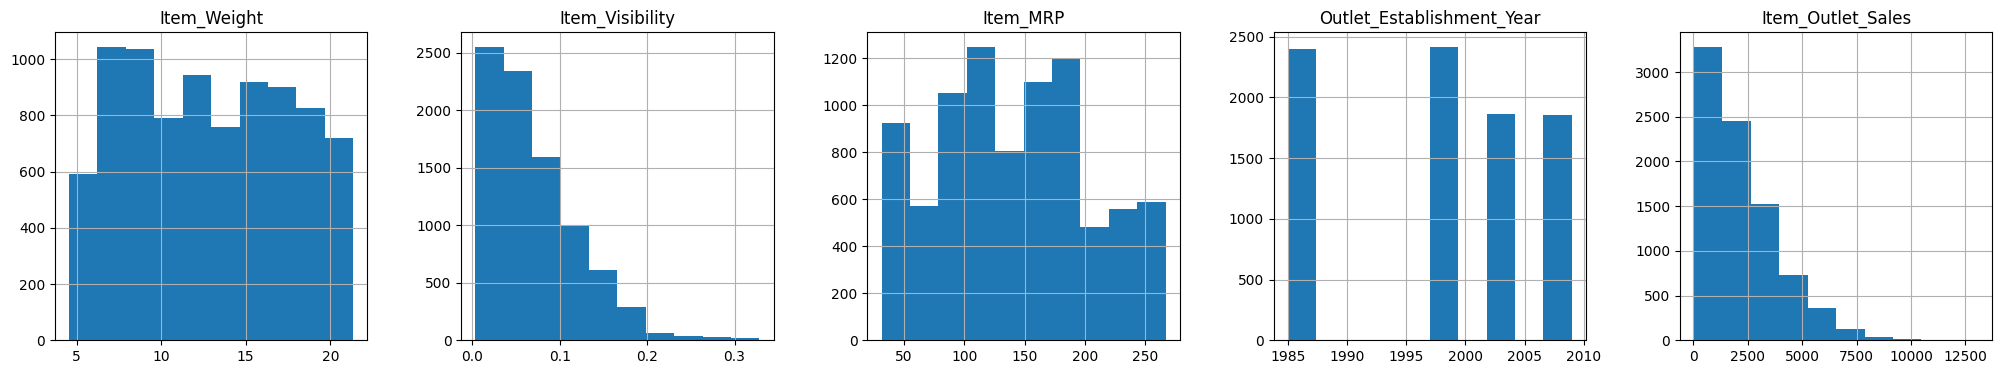

In [51]:
sales_df.hist(figsize=(25,4), layout=(1,5))
plt.show()

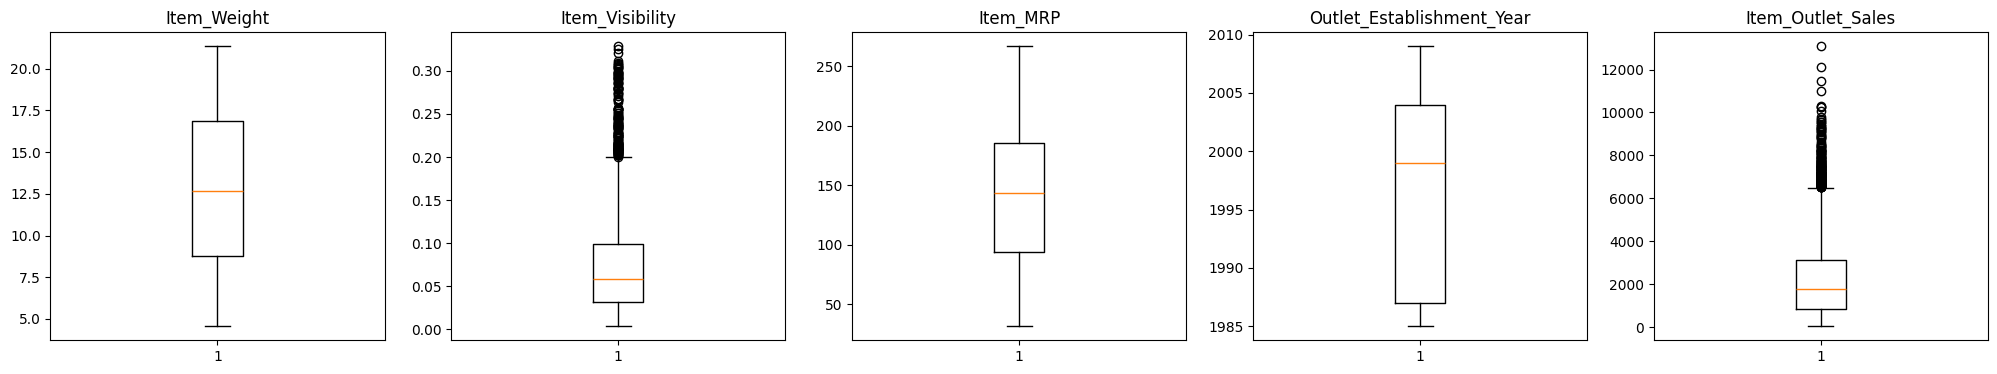

In [52]:
fig, axes = plt.subplots(1,5, figsize=(25,4))
axes = axes.ravel()
for col, ax in zip(num_cols, axes):
  ax.boxplot(sales_df[col].dropna())
  ax.set_title(col)
plt.show()

**Análisis univariado de variables categóricas**

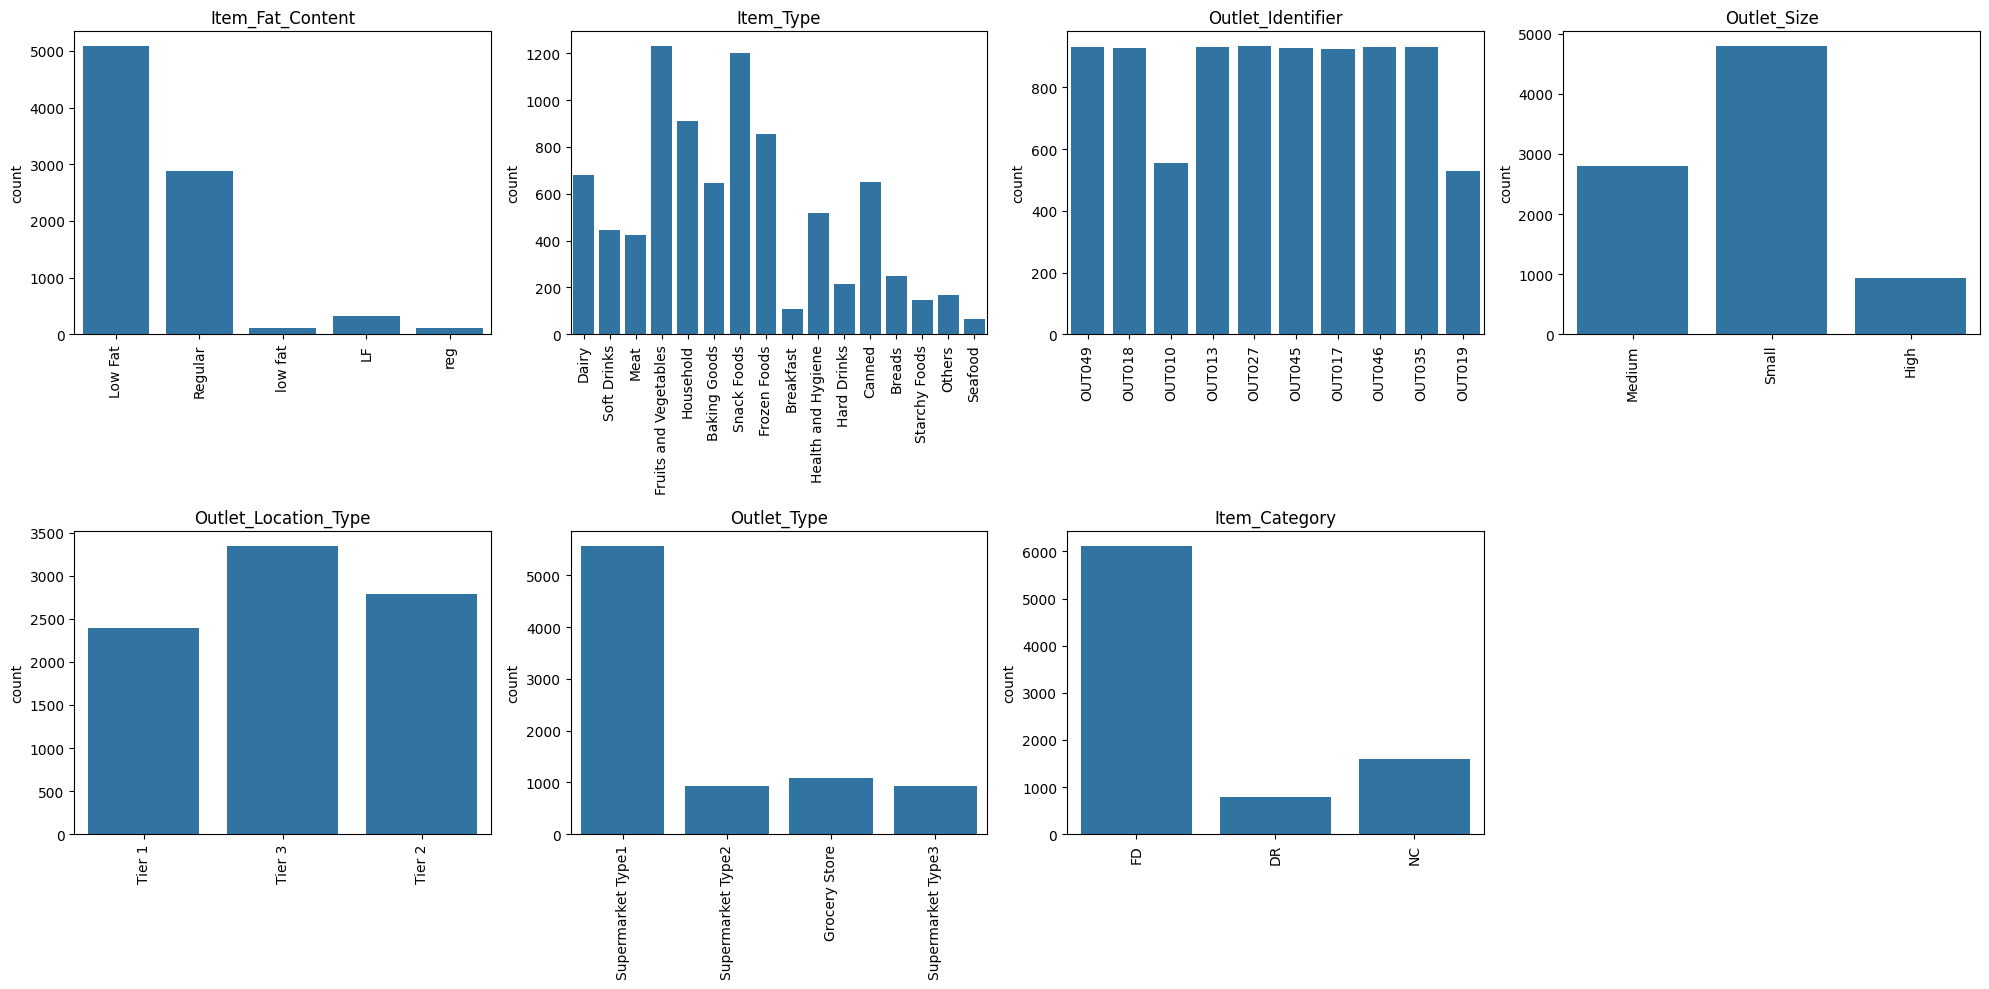

In [20]:
n = len(cat_cols)
fig, axes = plt.subplots(2, (n+1)//2, figsize=(5*((n+1)//2), 10))
axes = axes.ravel()
for col, ax in zip(cat_cols, axes):
  sns.countplot(x=sales_df[col], ax=ax)
  ax.set(title=f'{col}', xlabel=None)
  ax.tick_params(axis='x',rotation=90)
for ax in axes[n:]:
  ax.set_visible(False)
plt.tight_layout()
plt.show()

En `Item_Fat_Content` hay categorías expresadas de diferente forma:
*   Low Fat = low fat = LF
*   Regular = reg

Se unifica, para sólo dejar dos valores: Low Fat y Regular. Además, los productos no consumibles (`NC`) no pueden tener grasa, por lo que se les asigna la categoría `Non-Edible`.

In [21]:
sales_df['Item_Fat_Content'] = sales_df['Item_Fat_Content'].replace({'low fat':'Low Fat', 'LF':'Low Fat', 'reg':'Regular'})
sales_df.loc[sales_df['Item_Category']=='NC', 'Item_Fat_Content'] = 'Non-Edible'

<Axes: xlabel='Item_Fat_Content', ylabel='count'>

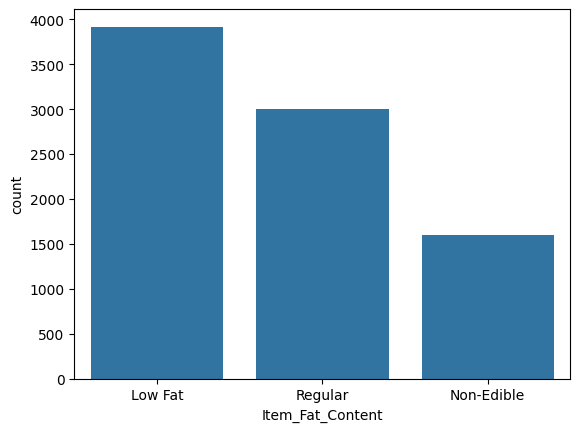

In [22]:
sns.countplot(x=sales_df['Item_Fat_Content'])

**Análisis bivariado**

<Axes: >

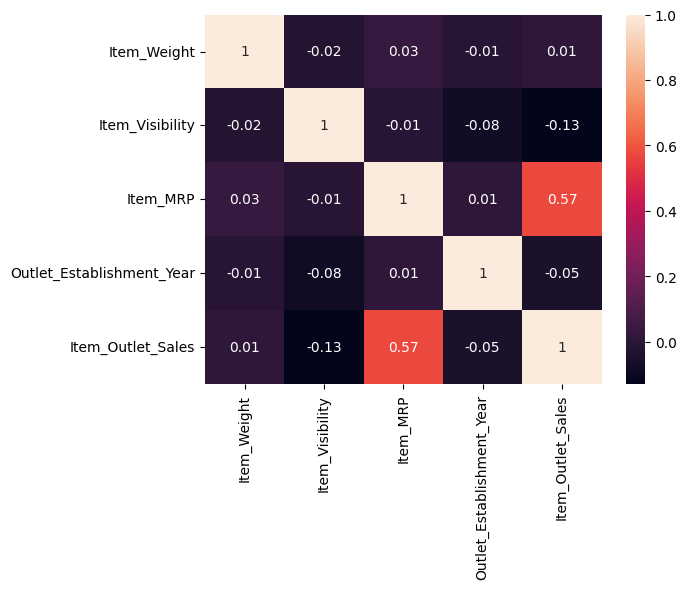

In [23]:
sns.heatmap(round(sales_df.corr(numeric_only=True),2), annot = True)

Del gráfico anterior, parece que solo la variable independiente `Item_MRP` tiene una relación lineal moderada con la variable dependiente `Item_Outlet_Sales`. Se verifica con diagramas de dispersión.

<Axes: xlabel='Item_MRP', ylabel='Item_Outlet_Sales'>

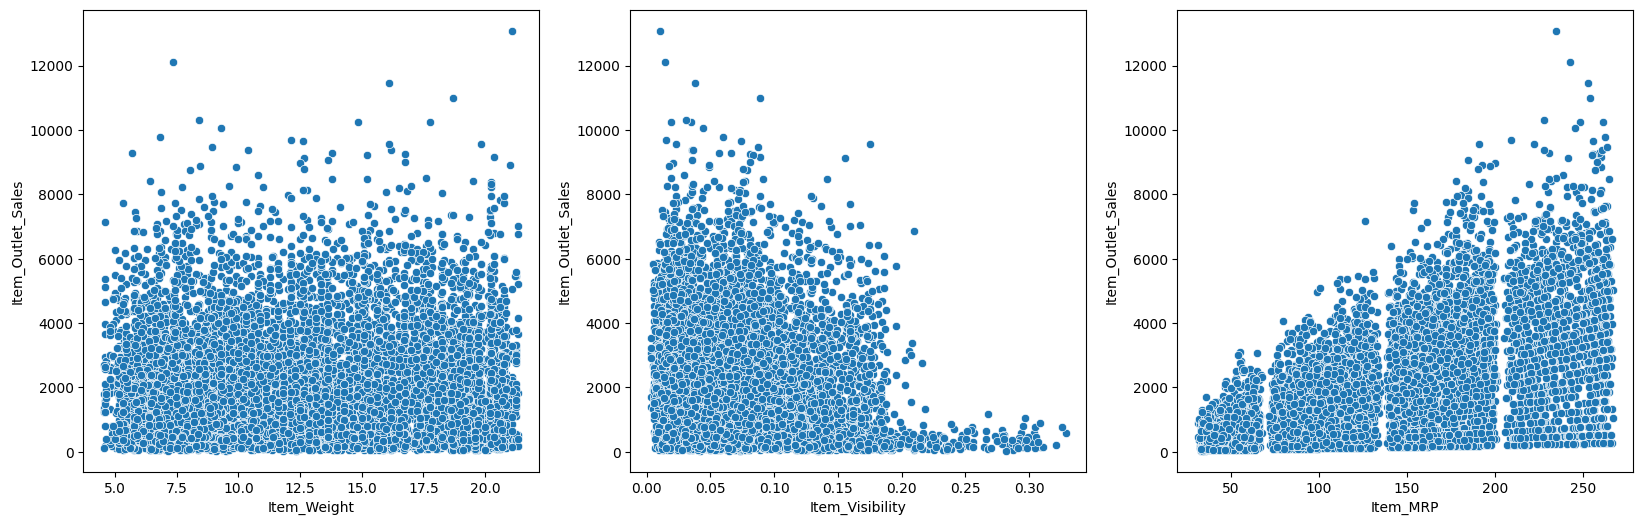

In [24]:
fig, axes = plt.subplots(1, 3, figsize = (20, 6))
sns.scatterplot(x='Item_Weight', y='Item_Outlet_Sales', data=sales_df, ax=axes[0])
sns.scatterplot(x='Item_Visibility', y='Item_Outlet_Sales', data=sales_df, ax=axes[1])
sns.scatterplot(x='Item_MRP', y='Item_Outlet_Sales', data=sales_df, ax=axes[2])

Se crea una nueva característica `Outlet_Age` que indica la antigüedad del outlet. Se usa 2013 como año de referencia (año de los datos) para que el resultado sea siempre reproducible, sin depender de la fecha en que se ejecute el notebook.

In [25]:
sales_df['Outlet_Age'] = 2013 - sales_df['Outlet_Establishment_Year'] #calcula la edad de cada tienda en años

sales_df.drop('Outlet_Establishment_Year', axis = 1, inplace=True) #elimina la columna original (ya fue transformada)

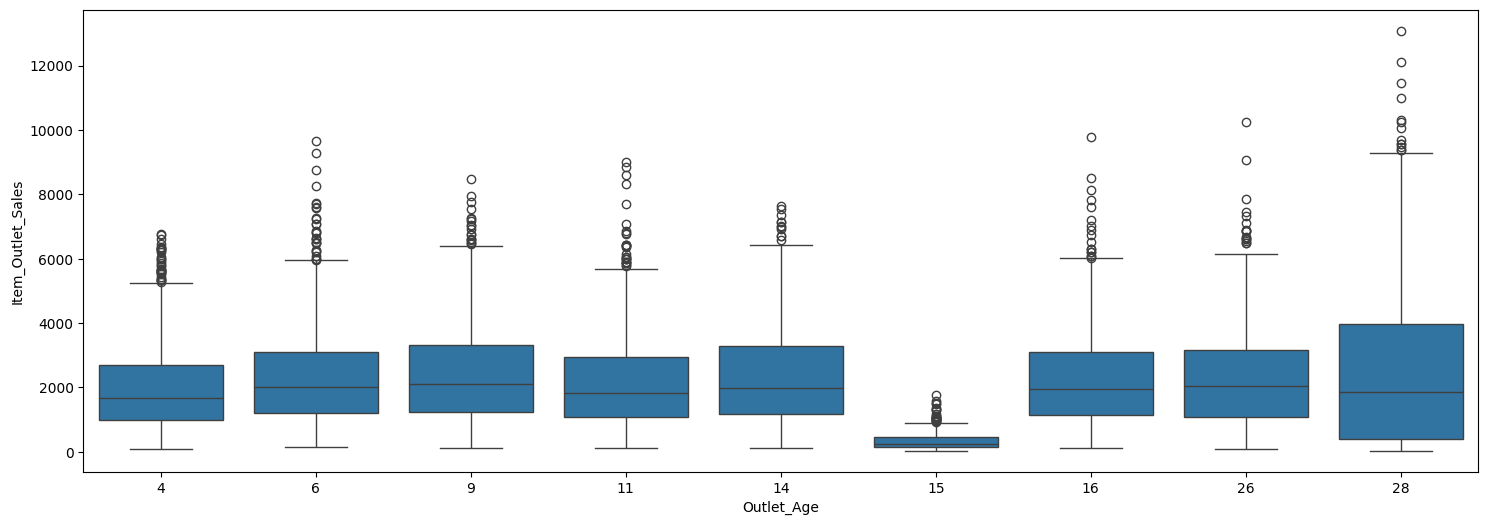

In [26]:
fig = plt.figure(figsize = (18, 6))
sns.boxplot(x = 'Outlet_Age', y = 'Item_Outlet_Sales', data = sales_df);

**INCIO MODELO MACHINE LEARNING**

**Transformaciones para mejorar el modelo**

1. `Item_Outlet_Sales` (la ventas) está muy sesgada a la derecha, por eso se modela su **logaritmo**. Esto hace que el error sea más parejo y que la relación con el precio sea más lineal.
2. Se usa `log(Item_MRP)` y `log(Item_Visibility)`.
3. Cada tienda tiene su propia relación entre precio y ventas, por lo que se crean **interacciones** `log(Item_MRP)` x tienda. Así la regresión sigue siendo lineal, pero con una pendiente de precio distinta por tienda.
4. Se eliminan `Item_Weight` e `Item_Type`: al probarlas, no aportan información útil (el peso no influye en las ventas y el tipo de producto ya queda resumido en `Item_Category`), solo agregan ruido al modelo.

In [27]:
# Transformación logarítmica de variables sesgadas
sales_df['Log_MRP'] = np.log(sales_df['Item_MRP'])
sales_df['Log_Visibility'] = np.log(sales_df['Item_Visibility'])
sales_df.drop(['Item_Visibility','Item_Weight','Item_Type'], axis=1, inplace=True)

# Interacción: efecto del precio distinto en cada tienda
for outlet in sorted(sales_df['Outlet_Identifier'].unique()):
    sales_df[f'Log_MRP_x_{outlet}'] = sales_df['Log_MRP'] * (sales_df['Outlet_Identifier'] == outlet)

sales_df.shape

(8523, 21)

INGENIERIA DE CARACTERISTICAS

Se especifican cuales seran las variables de entrada 'X' (Caracteristica) y cual sera la varible predictora 'y' (variable salida o
tambien Objetivo)

In [28]:
# Se separan las variables del dataframe: en X quedan los predictores y en y la variable de respuesta o salida (Item_Outlet_Sales).
X = sales_df.drop('Item_Outlet_Sales', axis = 1) #variables de entrada - Caracteristica
y = np.log(sales_df['Item_Outlet_Sales'])        #variable salida - Objetivo (en escala logarítmica)

**PARTICION DEL CONJUNTO DE DATOS**

In [29]:
# Se divide el conjunto en entrenamiento y prueba (80:20)
#80% conjunto de entrenamiento(train)
#20% para el conjunto de prueba (test)

from sklearn.model_selection import train_test_split

Xtrain, Xtest, ytrain, ytest = train_test_split(X,#variable entrada
                                                y,#variable salida o predictora
                                                train_size=0.8, # tama;o conjunto entrenamiento
                                                random_state=1) #para mantener mismo conjunto de datos

PROCESAMIENTO

**CANALIZACION (PIPELINE)**

In [30]:
# Como se aplicará más de un transformador y de manera diferenciada (numéricas y categóricas reciben diferentes tratamientos),
# hay que crear pipelines (aquí se nombraron como: num_pipeline y cat_pipeline) para transformar las columnas

#PARA VARIABLES NUMERICAS
num_pipeline = make_pipeline(SimpleImputer(strategy='median'), MinMaxScaler())
      #Rellena valores faltantes con la mediana
      #aplica escalado MinMaxScaler, para que todas los valores numericos esten en el rango [0,1]

#PARA VARIABLES CATEGORICAS
cat_pipeline = make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
      #Rellena valores faltantes con la categoria mas frecuente
      #Convierte categorias en columnas binarias (0,1) con OneHot
          #drop='first', evita la trampa de multicolinealidad, eliminando la primer categoria
          #handle_unknown='ignore', ignora nuevas categorias que no se vieron durante el entrenamiento
          #sparse_output=False, devuelve matriz densa

#UNE PREPROCESAMIENTOS
preprocessing = ColumnTransformer([
    ('num', num_pipeline, make_column_selector(dtype_include=np.number)), #detecta TODAS las columnas numericas
    ('cat', cat_pipeline, make_column_selector(dtype_exclude=np.number))])#detecta TODAS las columnas categoricas (texto)

In [31]:
# Esto no es necesario, pero se incluye para visualizar los cambios que produce el pipeline "preprocessing" creado anteriormente
Xtrain_prepared = preprocessing.fit_transform(Xtrain)
Xtrain_prepared_df = pd.DataFrame(Xtrain_prepared, columns=preprocessing.get_feature_names_out(), index=Xtrain.index)
print('Número de predictores después del procesamiento:', Xtrain_prepared_df.shape[1])
Xtrain_prepared_df

Número de predictores después del procesamiento: 34


,num__Item_MRP,num__Outlet_Age,num__Log_MRP,num__Log_Visibility,num__Log_MRP_x_OUT010,num__Log_MRP_x_OUT013,num__Log_MRP_x_OUT017,num__Log_MRP_x_OUT018,num__Log_MRP_x_OUT019,num__Log_MRP_x_OUT027,...,cat__Outlet_Identifier_OUT049,cat__Outlet_Size_Medium,cat__Outlet_Size_Small,cat__Outlet_Location_Type_Tier 2,cat__Outlet_Location_Type_Tier 3,cat__Outlet_Type_Supermarket Type1,cat__Outlet_Type_Supermarket Type2,cat__Outlet_Type_Supermarket Type3,cat__Item_Category_FD,cat__Item_Category_NC
1945,0.681925,0.000000,0.846238,0.712034,0.000000,0.0,0.000000,0.942083,0.000000,0.000000,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
1720,0.615374,0.000000,0.806484,0.851813,0.000000,0.0,0.000000,0.926813,0.000000,0.000000,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
1954,0.824788,0.083333,0.921612,0.600181,0.000000,0.0,0.970707,0.000000,0.000000,0.000000,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
1919,0.312702,0.000000,0.564630,0.844912,0.000000,0.0,0.000000,0.833913,0.000000,0.000000,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
2461,0.423207,0.208333,0.667998,0.622905,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2895,0.531008,1.000000,0.750669,0.962717,0.000000,0.0,0.000000,0.000000,0.904520,0.000000,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
7813,0.100619,1.000000,0.263096,0.864758,0.000000,0.0,0.000000,0.000000,0.717412,0.000000,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
905,0.500067,0.500000,0.728402,0.644399,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
5192,0.054833,0.458333,0.161239,0.581920,0.678279,0.0,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


**APLICA PREPROCESAMIENTO ANTERIOR PARA EL**

**ENTRENAMIENTO DEL MODELO REGRESION LINEAL**

In [32]:
# Se crea el pipeline para la predicción, que incluye el de procesamiento creado anteriormente y la regresión lineal
lr_model = make_pipeline(preprocessing, LinearRegression())

#ENTRENA Y AJUSTA TODO EL PIPELINE CON LOS DATOS DE ENTRENAMIENTO (ytrain está en escala logarítmica)
lr_model.fit(Xtrain, ytrain)

#PREDICCIONES SOBRE LOS DATOS DE PRUEBA
predictions = lr_model.predict(Xtest)

# --- Métricas en escala logarítmica (la escala en la que se entrenó el modelo) ---
print('R2 (escala logarítmica):', round(r2_score(ytest, predictions), 4))
print('RMSE (escala logarítmica):', round(np.sqrt(mean_squared_error(ytest, predictions)), 4))

# --- Métricas en la escala original de ventas ---
# Se regresa a ventas reales con exp() y se corrige el sesgo de la transformación log con el factor de Duan (smearing)
smearing = np.mean(np.exp(ytrain - lr_model.predict(Xtrain)))
pred_sales = np.exp(predictions) * smearing
real_sales = np.exp(ytest)
print('RMSE (ventas originales):', round(np.sqrt(mean_squared_error(real_sales, pred_sales)), 2))
print('R2 (ventas originales):', round(r2_score(real_sales, pred_sales), 4))

R2 (escala logarítmica): 0.7512
RMSE (escala logarítmica): 0.5247
RMSE (ventas originales): 1084.29
R2 (ventas originales): 0.6034


**Resultados:**

* **R² (escala logarítmica) ≈ 0.75**: el modelo explica cerca del 75% de la variabilidad de las ventas (en logaritmo). Es la escala en la que se entrenó el modelo.
* En la escala original de ventas, el R² es ≈ 0.60 y el RMSE ≈ 1,090, una mejora frente al modelo base (R² = 0.558 y RMSE = 1,144).

Nota: la diferencia entre ambos R² es normal. Al regresar de logaritmo a ventas reales, los errores de las ventas más altas pesan mucho más. Aun con modelos más complejos (Random Forest, Gradient Boosting) este dataset no pasa de ~0.60 en la escala original, por lo que el ruido propio de los datos es el límite.

Mejoras aplicadas respecto al modelo base:

* Limpieza de `Item_Visibility` (los 0 eran faltantes) y de `Item_Weight` / `Outlet_Size`.
* Se conservó `Outlet_Identifier` y se agregó `Item_Category`.
* Se aplicó logaritmo a ventas, precio (`Item_MRP`) y visibilidad.
* Se agregaron interacciones precio x tienda, que permiten que cada tienda tenga su propia pendiente de precio.
* Se eliminaron variables sin aporte (`Item_Weight`, `Item_Type`).

In [33]:
# Se puede tener acceso a los pasos ejecutados en el pipeline
lr_model.named_steps

{'columntransformer': ColumnTransformer(transformers=[('num',
                                  Pipeline(steps=[('simpleimputer',
                                                   SimpleImputer(strategy='median')),
                                                  ('minmaxscaler',
                                                   MinMaxScaler())]),
                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7c7e7f285be0>),
                                 ('cat',
                                  Pipeline(steps=[('simpleimputer',
                                                   SimpleImputer(strategy='most_frequent')),
                                                  ('onehotencoder',
                                                   OneHotEncoder(drop='first',
                                                                 handle_unknown='ignore',
                                                                 sparse_output=False))])

In [34]:
# Una vez ubicado en un paso, por ejemplo en la regresión lineal ('linearregression'), se puede tener acceso a sus atributos
# Para mostrar la intercepción o beta_0
lr_model.named_steps['linearregression'].intercept_

np.float64(5.008843566516402)

In [35]:
# Para mostrar los coeficientes: beta_1, beta_2, ... beta_n
# En este caso se obtienen 27 coeficientes, uno por predictor
lr_model.named_steps['linearregression'].coef_

array([-0.03184746,  0.04383366,  2.18699234, -0.00238257, -0.00881892,
        0.53302659,  0.3317404 ,  0.44536912,  0.16090756, -0.18407497,
        0.14264017, -0.18972728, -0.52618208,  0.13483995,  0.01350785,
        0.00973636, -0.00514409, -0.05906614,  0.20701918, -0.54874228,
        0.81182943,  0.13825059,  0.32586588,  1.05839616, -0.50864643,
        0.51020218, -0.5050581 ,  0.40505032, -0.40605778,  0.94965596,
        0.20701918,  0.81182943,  0.02487201,  0.01350785])

In [36]:
# Para mostrar los transformadores ejecutados
lr_model.named_steps['columntransformer']

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('minmaxscaler',
                                                  MinMaxScaler())]),
                                 <sklearn.compose._column_transformer.make_column_selector object at 0x7c7e7f285be0>),
                                ('cat',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehotencoder',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 <sklearn.compose._column_transformer.make_column_selector object at 0x7c7e7e8d5810>)])

In [37]:
# Para tener acceso a un transformador en particular
lr_model.named_steps['columntransformer'].named_transformers_['num']

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('minmaxscaler', MinMaxScaler())])

In [38]:
# Para tener acceso a los atributos de un transformador en particular
# Como sólo se tienen 4 predictores numéricos, se calcula el mínimo de cada uno
lr_model.named_steps['columntransformer'].named_transformers_['num'].named_steps['minmaxscaler'].min_

array([-0.13281075, -0.16666667, -1.60636673,  1.24634306,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ])